# Lab 9: Training an RL Agent

The question I'm working on: with the same CartPole and the same budget of 20,000 steps, which agent learns best, and which parts of DQN actually matter? I write DQN, two broken versions of it, REINFORCE with a baseline and PPO from scratch, using the starter unchanged for the environment, the networks and the measuring. Every agent runs on seeds 0, 1 and 2.

One detail matters all the way through: an episode can end because the pole fell (terminated) or because it hit the 200-step limit (truncated). Those aren't the same thing, and the best possible return is 200.

In [1]:
import copy
import hashlib
import json
import math
import os
import subprocess
import sys
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import lab09_starter as S

torch.set_num_threads(1)          # tiny networks: one thread is faster and makes runs bit-reproducible

SEEDS = [0, 1, 2]
BUDGET = S.BUDGET                 # 20,000 environment steps for every agent
LEVEL = 150                       # "first step at which the smoothed return reaches 150"
# DQN (piece 2)
DQN_SETTINGS = dict(eps_start=1.0, eps_end=0.05, eps_decay_steps=8000, buffer_capacity=20000, warmup=500,
                    batch_size=64, learning_rate=1e-3, gamma=0.99, grad_clip=10.0, target_every=250)
# REINFORCE and PPO (piece 4)
REINFORCE_SETTINGS = dict(episodes_per_update=8, policy_lr=3e-3, value_lr=1e-2, gamma=0.99)
PPO_SETTINGS = dict(rollout_steps=1024, epochs=6, minibatch_size=128, clip=0.2, gamma=0.99, lam=0.95,
                    learning_rate=3e-4, value_coef=0.5, grad_clip=0.5, entropy_coef=0.0)
Q_PROBE_EVERY = 1000
Q_BOUND = 1.0 / (1.0 - DQN_SETTINGS["gamma"])   # 100
PROBES = S.probe_states()          # 500 fixed states, collected once before any training, shared by every run
assert tuple(PROBES.shape) == (500, 4)
os.makedirs("figures", exist_ok=True)
results = {"settings": {"dqn": DQN_SETTINGS, "reinforce": REINFORCE_SETTINGS, "ppo": PPO_SETTINGS,
                        "q_probe_every": Q_PROBE_EVERY, "q_bound": Q_BOUND, "level": LEVEL,
                        "seeds": SEEDS, "budget": BUDGET,
                        "torch_threads": torch.get_num_threads(), "torch_version": torch.__version__},
           "piece_seconds": {}, "checks": {}, "runs": {}}
results["probe_states_sha256"] = hashlib.sha256(PROBES.numpy().tobytes()).hexdigest()
notebook_start = time.perf_counter()
print("probe states:", tuple(PROBES.shape), "sha256", results["probe_states_sha256"][:16])

probe states: (500, 4) sha256 2037ff1df2cdef2f


In [2]:
def to_jsonable(x):
    """nan/inf -> None, numpy -> python, recursively."""
    if isinstance(x, dict):
        return {str(key): to_jsonable(value) for key, value in x.items()}
    if isinstance(x, (list, tuple)):
        return [to_jsonable(value) for value in x]
    if isinstance(x, np.ndarray):
        return to_jsonable(x.tolist())
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (bool, np.bool_)):
        return bool(x)
    if isinstance(x, (float, np.floating)):
        return float(x) if np.isfinite(x) else None
    return x

def make_run_record(episodes, wall_seconds, **extras):
    curve = S.smooth_curve(episodes)
    return {"episodes": [[int(t), float(r)] for t, r in episodes],
            "curve": [None if not np.isfinite(v) else float(v) for v in curve],
            "final_return": S.final_return(episodes),
            "steps_to_150": S.steps_to_reach(curve, LEVEL),
            "n_episodes": len(episodes), "total_env_steps": BUDGET, "wall_seconds": wall_seconds, **extras}

def curve_array(record):
    return np.array([np.nan if v is None else v for v in record["curve"]])

def save_results(results, path="lab9_results.json"):
    with open(path, "w") as results_file:
        json.dump(to_jsonable(results), results_file, indent=1)

def show(fig, path=None):
    """Save the figure if a path is given, and display it when running in a notebook."""
    if path is not None:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    if "ipykernel" in sys.modules:
        import io
        from IPython.display import Image, display
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
        display(Image(data=buffer.getvalue()))
    plt.close(fig)

## Run the starter once

Before writing anything I run the starter as given, to check the environment and to see what a random policy scores.

In [3]:
starter_run = subprocess.run([sys.executable, "lab09_starter.py"], capture_output=True, text=True, check=True)
print(starter_run.stdout)
results["starter"] = {"stdout": starter_run.stdout.strip(),
                      "random_mean_return": float(starter_run.stdout.split("mean return ")[1].split()[0])}

random policy: mean return 22.2 over 50 episodes (best possible is 200)
probe states: (500, 4)
saved starter_check.png



A random policy averages 22.2 over 50 episodes, a long way from 200. The starter also gives 500 probe states. I take them once, before any training, so every agent and seed has its Q-values measured on the same states.

## Piece 1: the losses, written and checked

Every agent depends on a few small formulas, and a wrong one usually still trains, just badly. So before any agent runs I check each one against numbers I can work out by hand.

In [4]:
def stored_done_flag(terminated, truncated):
    """Flag stored with a transition. Only a true terminal (pole fell / cart left) stops the bootstrap.
    A time-limit truncation is not terminal: the state still has a future, the episode was just cut."""
    return float(terminated)

def dqn_target(rewards, next_q_values, dones, gamma):
    """y_i = r_i + gamma * (1 - done_i) * max_a' Q(s'_i, a').
    rewards, dones: (B,) float32. next_q_values: (B, n_actions) from the bootstrap network,
    which the CALLER computes inside torch.no_grad(). Returns (B,)."""
    return rewards + gamma * (1.0 - dones) * next_q_values.max(dim=1).values

def huber_loss(errors, delta=1.0):
    """Elementwise Huber: 0.5 e^2 if |e| <= delta, else delta * (|e| - 0.5 delta). No reduction."""
    abs_errors = errors.abs()
    return torch.where(abs_errors <= delta, 0.5 * errors ** 2, delta * (abs_errors - 0.5 * delta))

def ppo_clip_objective(ratio, advantages, clip=0.2):
    """Per-sample PPO surrogate, higher is better: min(r * A, clip(r, 1 - eps, 1 + eps) * A)."""
    return torch.minimum(ratio * advantages, torch.clamp(ratio, 1 - clip, 1 + clip) * advantages)

def returns_to_go(rewards, gamma):
    """G_t = r_t + gamma * G_{t+1}, G after the last reward = 0. Returns float32 numpy array."""
    running_return, out = 0.0, np.zeros(len(rewards), np.float32)
    for i in reversed(range(len(rewards))):
        running_return = rewards[i] + gamma * running_return
        out[i] = running_return
    return out

def gae_advantages(rewards, values, next_values, terminated, episode_ended, gamma, lam):
    """Generalized advantage estimation over one rollout (numpy float32 arrays, length n).
    values[i] = V(s_i); next_values[i] = V(s_{i+1}) where s_{i+1} is the state step() returned
    (BEFORE any reset), computed at collection time under no_grad.
    delta_i = r_i + gamma * (1 - terminated_i) * next_values[i] - values[i]
    A_i     = delta_i + gamma * lam * (1 - episode_ended_i) * A_{i+1},  with A_n = 0.
    episode_ended_i = terminated_i or truncated_i (the recursion must not cross an episode boundary,
    but a truncated step still bootstraps through next_values[i]). Returns advantages (n,)."""
    advantages = np.zeros(len(rewards), np.float32)
    next_advantage = 0.0
    for i in reversed(range(len(rewards))):
        delta = rewards[i] + gamma * (1.0 - terminated[i]) * next_values[i] - values[i]
        next_advantage = delta + gamma * lam * (1.0 - episode_ended[i]) * next_advantage
        advantages[i] = next_advantage
    return advantages

### Check 1: when the target bootstraps

The DQN target is r + gamma × max Q(next state), unless the episode really ended. The trap is the time limit: reaching step 200 isn't the pole falling, so the target should still bootstrap. I test four cases with reward 1, a next value of 7 and discount 0.9, next to the two ways of getting it wrong.

In [5]:
rewards = torch.tensor([1.0, 1.0, 1.0, 1.0])
next_q = torch.tensor([[7.0, 2.0]] * 4)            # largest next value 7
cases = [("terminal (pole fell)", True, False),
         ("non-terminal", False, False),
         ("time limit only (truncated)", False, True),
         ("pole fell on step 200 (both flags)", True, True)]
dones = torch.tensor([stored_done_flag(term, trunc) for _, term, trunc in cases])
targets = dqn_target(rewards, next_q, dones, gamma=0.9)
expected = [1.0, 7.3, 7.3, 1.0]
# the BUG versions: truncation treated as terminal, and a true terminal that still bootstraps
bug_truncation_dones = torch.tensor([float(term or trunc) for _, term, trunc in cases])
bug_truncation_targets = dqn_target(rewards, next_q, bug_truncation_dones, gamma=0.9)
bug_no_terminal_targets = dqn_target(rewards, next_q, torch.zeros(4), gamma=0.9)
print("reward 1, largest next value 7, discount 0.9")
print(f"{'case':38s} {'stored done':>11s} {'target':>9s} {'expected':>9s} {'bug: trunc=terminal':>20s} {'bug: never terminal':>20s}")
for i, (name, term, trunc) in enumerate(cases):
    print(f"{name:38s} {float(dones[i]):11.1f} {float(targets[i]):9.6f} {expected[i]:9.6f} "
          f"{float(bug_truncation_targets[i]):20.6f} {float(bug_no_terminal_targets[i]):20.6f}")
bootstrap_error = max(abs(float(targets[i]) - expected[i]) for i in range(4))
bootstrap_passed = bootstrap_error < 1e-5
print("max |target - expected| =", f"{bootstrap_error:.2e}", "->", "PASS" if bootstrap_passed else "FAIL")
results["checks"]["bootstrap"] = {"cases": [c[0] for c in cases], "targets": targets.tolist(), "expected": expected,
                                  "bug_truncation_as_terminal": bug_truncation_targets.tolist(),
                                  "bug_always_bootstrap": bug_no_terminal_targets.tolist(),
                                  "passed": bool(bootstrap_passed)}

reward 1, largest next value 7, discount 0.9
case                                   stored done    target  expected  bug: trunc=terminal  bug: never terminal
terminal (pole fell)                           1.0  1.000000  1.000000             1.000000             7.300000
non-terminal                                   0.0  7.300000  7.300000             7.300000             7.300000
time limit only (truncated)                    0.0  7.300000  7.300000             1.000000             7.300000
pole fell on step 200 (both flags)             1.0  1.000000  1.000000             1.000000             7.300000
max |target - expected| = 2.86e-07 -> PASS


The non-terminal and time-limit cases both give 1 + 0.9 × 7 = 7.3, and only a real terminal gives 1.0, so the target is right. The two bugs show why it matters:

- **Truncation stored as terminal:** the same state gets 1.0 at step 200 and 7.3 any other time. Time isn't part of the state, so the network sees contradictory targets.
- **Terminal that bootstraps:** falling is worth 7.3 instead of 1.0, so the agent never learns that falling ends the reward.

### Check 2: Huber loss

I compare my Huber loss with a hand calculation and with PyTorch's two built-in versions at errors of 0.5, 3 and -3, which covers both the quadratic and the linear part.

In [6]:
huber_errors = torch.tensor([0.5, 3.0, -3.0])
by_hand = [0.5 * 0.5 ** 2, 1.0 * (3.0 - 0.5), 1.0 * (3.0 - 0.5)]      # 0.125, 2.5, 2.5
mine = huber_loss(huber_errors)
torch_huber = F.huber_loss(huber_errors, torch.zeros(3), reduction="none", delta=1.0)
torch_smooth_l1 = F.smooth_l1_loss(huber_errors, torch.zeros(3), reduction="none", beta=1.0)
print(f"{'error':>6s} {'by hand':>9s} {'mine':>9s} {'F.huber_loss':>13s} {'F.smooth_l1_loss':>17s}")
for i in range(3):
    print(f"{float(huber_errors[i]):6.1f} {by_hand[i]:9.6f} {float(mine[i]):9.6f} {float(torch_huber[i]):13.6f} {float(torch_smooth_l1[i]):17.6f}")
huber_gap = max(float((mine - torch.tensor(by_hand)).abs().max()), float((mine - torch_huber).abs().max()),
                float((mine - torch_smooth_l1).abs().max()))
huber_passed = huber_gap < 1e-7
print("largest disagreement between the four:", f"{huber_gap:.2e}", "->", "PASS" if huber_passed else "FAIL")
results["checks"]["huber"] = {"errors": huber_errors.tolist(), "by_hand": by_hand, "mine": mine.tolist(),
                              "torch_huber": torch_huber.tolist(), "torch_smooth_l1": torch_smooth_l1.tolist(),
                              "largest_gap": huber_gap, "passed": bool(huber_passed)}

 error   by hand      mine  F.huber_loss  F.smooth_l1_loss
   0.5  0.125000  0.125000      0.125000          0.125000
   3.0  2.500000  2.500000      2.500000          2.500000
  -3.0  2.500000  2.500000      2.500000          2.500000
largest disagreement between the four: 0.00e+00 -> PASS


All four agree exactly: 0.125 at 0.5 and 2.5 at both 3 and -3, so it's symmetric and grows linearly past delta = 1. The handout doesn't give a delta, so I used 1, the PyTorch default.

### Check 3: the fixed point, with and without a target network

A single state that always returns to itself with reward 1 and discount 0.9 has a true value of exactly 10. I train Q on it for 3,000 updates twice: once with a target network refreshed every 50 updates, and once without one. That shows whether my target network works, and what it costs.

--- with_target (true value 10) ---
value at updates: 0: -0.0796, 50: 0.8917, 100: 1.8231, 200: 3.3403, 500: 6.4496, 1000: 8.7642, 1500: 9.5680, 2000: 9.8490, 2500: 9.9476, 3000: 9.9827
final 9.9827   mean of last 100 9.9779   last 500 min 9.8897 max 10.0575
first update with |value - 10| < 0.1: 2101   target refreshes: 60


--- without_target (true value 10) ---
value at updates: 0: -0.0796, 50: 10.4150, 100: 9.9459, 200: 10.0003, 500: 10.0000, 1000: 10.0000, 1500: 10.0000, 2000: 10.0000, 2500: 10.0000, 3000: 10.0000
final 10.0000   mean of last 100 10.0000   last 500 min 10.0000 max 10.0000
first update with |value - 10| < 0.1: 15   target refreshes: 0
target arm criterion (|mean last 100 - 10| < 0.5 and 60 refreshes): PASS (the no-target arm has no pass criterion)


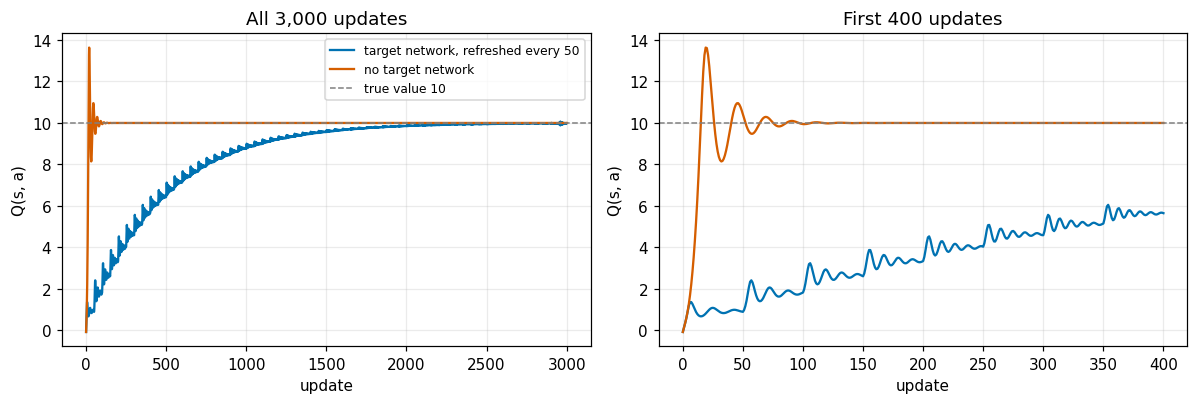

In [7]:
def fixed_point_run(use_target, n_updates=3000, refresh_every=50, learning_rate=0.01, gamma=0.9, seed=0):
    """One state, one action, reward 1, next state = same state, never terminal. True value 1/(1-0.9) = 10.
    Returns the value Q(s, a) after every update (length n_updates + 1, index 0 = before training)
    and the number of target refreshes."""
    S.set_seed(seed)
    q_net = S.QNet(n_actions=1)                      # one action, so max over actions is that action
    target_net = copy.deepcopy(q_net)
    optimizer = torch.optim.Adam(q_net.parameters(), lr=learning_rate)
    state = PROBES[0:1].clone()                      # a real CartPole state, fixed
    action = torch.tensor([0]); reward = torch.tensor([1.0]); done = torch.tensor([0.0])
    n_refreshes = 0
    with torch.no_grad():
        values = [float(q_net(state)[0, 0])]
    for update in range(1, n_updates + 1):
        with torch.no_grad():
            bootstrap_net = target_net if use_target else q_net
            target = dqn_target(reward, bootstrap_net(state), done, gamma)
        prediction = q_net(state).gather(1, action[:, None])[:, 0]
        loss = huber_loss(prediction - target).mean()
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        if use_target and update % refresh_every == 0:
            target_net.load_state_dict(q_net.state_dict())
            n_refreshes += 1
        with torch.no_grad():
            values.append(float(q_net(state)[0, 0]))
    return values, n_refreshes

REPORT_UPDATES = [0, 50, 100, 200, 500, 1000, 1500, 2000, 2500, 3000]
fixed_point = {}
for arm_name, use_target in [("with_target", True), ("without_target", False)]:
    values, n_refreshes = fixed_point_run(use_target)
    values_array = np.array(values)
    within = np.where(np.abs(values_array - 10.0) < 0.1)[0]
    fixed_point[arm_name] = {
        "trajectory": values,
        "at_updates": {str(u): values[u] for u in REPORT_UPDATES},
        "final": values[-1], "mean_last_100": float(values_array[-100:].mean()),
        "min_last_500": float(values_array[-500:].min()), "max_last_500": float(values_array[-500:].max()),
        "first_update_within_0.1": int(within[0]) if len(within) else None,
        "n_refreshes": n_refreshes}
    record = fixed_point[arm_name]
    print(f"--- {arm_name} (true value 10) ---")
    print("value at updates:", ", ".join(f"{u}: {values[u]:.4f}" for u in REPORT_UPDATES))
    print(f"final {record['final']:.4f}   mean of last 100 {record['mean_last_100']:.4f}   "
          f"last 500 min {record['min_last_500']:.4f} max {record['max_last_500']:.4f}")
    print("first update with |value - 10| < 0.1:", record["first_update_within_0.1"] if len(within) else "never",
          "  target refreshes:", n_refreshes)
fixed_point_passed = (abs(fixed_point["with_target"]["mean_last_100"] - 10.0) < 0.5
                      and fixed_point["with_target"]["n_refreshes"] == 60
                      and fixed_point["without_target"]["n_refreshes"] == 0)
print("target arm criterion (|mean last 100 - 10| < 0.5 and 60 refreshes):", "PASS" if fixed_point_passed else "FAIL",
      "(the no-target arm has no pass criterion)")
results["checks"]["fixed_point"] = {"with_target": {k: v for k, v in fixed_point["with_target"].items() if k != "trajectory"},
                                    "without_target": {k: v for k, v in fixed_point["without_target"].items() if k != "trajectory"},
                                    "trajectory_with_target": fixed_point["with_target"]["trajectory"],
                                    "trajectory_without_target": fixed_point["without_target"]["trajectory"],
                                    "passed": bool(fixed_point_passed)}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, x_limit in zip(axes, [3000, 400]):
    ax.plot(fixed_point["with_target"]["trajectory"][:x_limit + 1], color="#0072B2", label="target network, refreshed every 50")
    ax.plot(fixed_point["without_target"]["trajectory"][:x_limit + 1], color="#D55E00", label="no target network")
    ax.axhline(10.0, ls="--", color="grey", lw=1, label="true value 10")
    ax.set_xlabel("update"); ax.set_ylabel("Q(s, a)"); ax.grid(alpha=0.25)
axes[0].set_title("All 3,000 updates"); axes[1].set_title("First 400 updates"); axes[0].legend(fontsize=8)
fig.tight_layout()
show(fig, "figures/fixed_point.png")

**With a target network:** Q climbs in a staircase, one step per refresh, and reaches 9.98 by update 3,000. It first gets within 0.1 of 10 at update 2,101, after 60 refreshes in total.

**Without one:** I expected trouble and didn't get any. Q overshot to 13.6, dipped, and settled at exactly 10 by about update 130. A single state that bootstraps from itself just oscillates and converges.

So this check can't show the instability DQN has across many states, and I don't claim it does. What it does show is the cost of the target network: about 2,100 updates to converge instead of about 130.

### Check 4: PPO clipped objective

PPO's clip should stop the policy moving too far in the direction the advantage likes, but still fully punish a bad move. I check ratios of 1.3 and 0.7 with advantages of +1 and -1 against values I worked out by hand.

In [8]:
clip_ratios = torch.tensor([1.3, 1.3, 0.7, 0.7])
clip_advantages = torch.tensor([1.0, -1.0, 1.0, -1.0])
clip_by_hand = [1.2,    # min(1.3 * 1, 1.2 * 1) = min(1.3, 1.2)
                -1.3,   # min(1.3 * -1, 1.2 * -1) = min(-1.3, -1.2)
                0.7,    # min(0.7 * 1, 0.8 * 1) = min(0.7, 0.8)
                -0.8]   # min(0.7 * -1, 0.8 * -1) = min(-0.7, -0.8)
clip_mine = ppo_clip_objective(clip_ratios, clip_advantages, clip=0.2)
print(f"{'ratio':>6s} {'advantage':>10s} {'by hand':>9s} {'mine':>9s}")
for i in range(4):
    print(f"{float(clip_ratios[i]):6.1f} {float(clip_advantages[i]):10.1f} {clip_by_hand[i]:9.4f} {float(clip_mine[i]):9.4f}")
clip_gap = float((clip_mine - torch.tensor(clip_by_hand)).abs().max())
ppo_clip_passed = clip_gap < 1e-6
print("largest gap:", f"{clip_gap:.2e}", "->", "PASS" if ppo_clip_passed else "FAIL")
results["checks"]["ppo_clip"] = {"ratios": clip_ratios.tolist(), "advantages": clip_advantages.tolist(),
                                 "by_hand": clip_by_hand, "mine": clip_mine.tolist(), "passed": bool(ppo_clip_passed)}

 ratio  advantage   by hand      mine
   1.3        1.0    1.2000    1.2000
   1.3       -1.0   -1.3000   -1.3000
   0.7        1.0    0.7000    0.7000
   0.7       -1.0   -0.8000   -0.8000
largest gap: 0.00e+00 -> PASS


All four match. At ratio 1.3 with a positive advantage the objective is capped at 1.2, but with a negative advantage it stays at -1.3. Ratio 0.7 mirrors that (0.7 and -0.8). So the clip only removes the reward for overshooting and leaves the penalty side alone.

### Check 5: return-to-go

REINFORCE needs the discounted return from each step to the end of the episode. Rewards 1, 1, 1 with discount 0.5 should give 1.75, 1.5 and 1.0.

In [9]:
rtg_mine = returns_to_go([1.0, 1.0, 1.0], 0.5)
rtg_by_hand = [1.75, 1.5, 1.0]        # 1 + 0.5 * 1.5, 1 + 0.5 * 1, 1
print("rewards [1, 1, 1], discount 0.5")
print("mine:   ", [float(v) for v in rtg_mine])
print("by hand:", rtg_by_hand)
rtg_passed = bool(np.abs(rtg_mine - np.array(rtg_by_hand)).max() < 1e-6)
print("->", "PASS" if rtg_passed else "FAIL")
results["checks"]["return_to_go"] = {"mine": [float(v) for v in rtg_mine], "by_hand": rtg_by_hand, "passed": rtg_passed}

rewards [1, 1, 1], discount 0.5
mine:    [1.75, 1.5, 1.0]
by hand: [1.75, 1.5, 1.0]
-> PASS


It gives 1.75, 1.5 and 1.0, matching the hand calculation.

### Check 6 (extra): advantage estimation at episode ends

The handout doesn't ask for this, but GAE is where a time-limit bug would hide in PPO, so I check it the same way: a truncated step should still bootstrap from the next state's value, a terminated step shouldn't, and the recursion should never cross from one episode into the next.

In [10]:
gae_cases = [
    ("three steps, terminal at end", [1, 1, 1], [0, 0, 0], [0, 0, 1], [0, 0, 1], [1.3125, 1.25, 1.0]),
    ("truncated last step bootstraps", [1, 1], [0, 2], [0, 0], [0, 1], [1.5, 2.0]),
    ("terminated last step", [1, 1], [0, 0], [0, 1], [0, 1], [1.25, 1.0]),
    ("boundary after step 0", [1, 1], [0, 0], [1, 0], [1, 0], [1.0, 1.0]),
]
gae_passed = True
gae_rows = []
for name, case_rewards, case_next_values, case_terminated, case_ended, case_expected in gae_cases:
    got = gae_advantages(np.array(case_rewards, np.float32), np.zeros(len(case_rewards), np.float32),
                         np.array(case_next_values, np.float32), np.array(case_terminated, np.float32),
                         np.array(case_ended, np.float32), gamma=0.5, lam=0.5)
    case_ok = bool(np.abs(got - np.array(case_expected)).max() < 1e-6)
    gae_passed = gae_passed and case_ok
    gae_rows.append({"case": name, "mine": [float(v) for v in got], "expected": case_expected, "passed": case_ok})
    print(f"{name:34s} mine {[round(float(v), 4) for v in got]}  expected {case_expected}  {'PASS' if case_ok else 'FAIL'}")
results["checks"]["gae"] = {"cases": gae_rows, "passed": bool(gae_passed)}

three steps, terminal at end       mine [1.3125, 1.25, 1.0]  expected [1.3125, 1.25, 1.0]  PASS
truncated last step bootstraps     mine [1.5, 2.0]  expected [1.5, 2.0]  PASS
terminated last step               mine [1.25, 1.0]  expected [1.25, 1.0]  PASS
boundary after step 0              mine [1.0, 1.0]  expected [1.0, 1.0]  PASS


All four cases match. The truncated step bootstraps (1.5 and 2.0), the terminated one doesn't, and nothing leaks across the episode boundary.

### All checks

In [11]:
results["checks"]["all_passed"] = all(results["checks"][name]["passed"] for name in
    ["bootstrap", "huber", "fixed_point", "ppo_clip", "return_to_go", "gae"])
print("all piece 1 checks passed:", results["checks"]["all_passed"])
results["piece_seconds"]["checks"] = time.perf_counter() - notebook_start
save_results(results)
assert results["checks"]["all_passed"], "a piece 1 check failed: fix it before any agent runs"

all piece 1 checks passed: True


All six checks pass, so I move on to the agents. The fixed-point check only has a pass criterion for the target-network version; the no-target version is just reported.